In [1]:
%pip install numpy pandas matplotlib tensorflow scikit-learn
from pathlib import Path  # Work with file and folder paths
import json              # Read and write JSON files
import time              # Measure training time

import numpy as np       # Work with arrays and numbers
import pandas as pd      # Work with tables and datasets
import matplotlib.pyplot as plt  # Create graphs
import tensorflow as tf  # Machine learning framework

from sklearn.metrics import (
    classification_report,  # Precision, recall, F1-score, accuracy
    confusion_matrix,       # Compare actual and predicted classes
    ConfusionMatrixDisplay  # Display the confusion matrix as a graph
)

from sklearn.utils.class_weight import compute_class_weight  # Balance class importance

from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
# ModelCheckpoint saves the best model
# EarlyStopping stops training when validation performance stops improving

# Keras is a Python API that makes it easier to build and train neural networks.
# It is included in TensorFlow through tf.keras.

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp312-cp312-win_amd64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp312-cp312-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl (8.3 MB)
Using cached 

In [2]:
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")
FIGURES_DIR = Path("../reports/figures")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 10 # how many times the model goes through the entire training dataset.
BATCH_SIZE=8 # number of img proccessed before updating the weights 

with open(PROCESSED_DIR / 'labels.json') as file:
    label_mapping = json.load(file)


class_names = [
    label_mapping[str(i)]
    for i in range(len(label_mapping))
]

print("Classes:", class_names)

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [3]:
train_data = np.load(PROCESSED_DIR / "train.npz")
val_data = np.load(PROCESSED_DIR / "val.npz")
test_data = np.load(PROCESSED_DIR / "test.npz")

X_train = train_data["X"]
y_train = train_data["y"]

X_val = val_data["X"]
y_val = val_data["y"]

X_test = test_data["X"]
y_test = test_data["y"]

train_data.close()
val_data.close()
test_data.close()

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:",X_test.shape)



Train: (4617, 224, 224, 3)
Validation: (990, 224, 224, 3)
Test: (990, 224, 224, 3)


In [5]:
# load the cnn 
model = tf.keras.models.load_model(
    MODELS_DIR / "cnn_initial.keras"
)

model.summary()

c:\Users\ycode\Desktop\brainscan-ai\.venv312\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 22 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(store)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 21632)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,384,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,197,326 (16.01 MB)

 Trainable params: 1,399,108 (5.34 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,798,218 (10.67 MB)

In [6]:
# calculate class weights

classes = np.unique(y_train)


weight = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y= y_train
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes, weight)
}

print("Class weights:", class_weights)

# Without class weights, the model may focus more on classes with many images.
# Class weights help give more importance to the underrepresented classes.
# Few images: higher weight, so mistakes on this class matter more.
# Many images: lower weight, so it doesn't dominate training.

Class weights: {0: 1.0178571428571428, 1: 1.0777310924369747, 2: 0.9667085427135679, 3: 0.9476600985221675}


In [7]:
# creates callbacks that help your CNN save the best model 
# and stop training when it stops improving.

checkpoint = ModelCheckpoint(
    filepath=str(MODELS_DIR / "best_model.keras"),
    monitor="val_loss",
    save_best_only=True,
    mode="min"
)
# stop unnecessary training
# If validation loss doesn't improve for 3 epochs,
# training stops early instead of continuing all 10 epochs.
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

callbacks = [checkpoint, early_stopping]

In [8]:
# Train the cnn

start_time = time.time()

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    class_weight=class_weights
)

training_time = time.time() - start_time


print(f"Training time: { training_time:.2f} seconds")

Epoch 1/10
578/578 ━━━━━━━━━━━━━━━━━━━━ 30s 50ms/step - accuracy: 0.7072 - loss: 0.7183 - val_accuracy: 0.8172 - val_loss: 0.4212
Epoch 2/10
578/578 ━━━━━━━━━━━━━━━━━━━━ 27s 48ms/step - accuracy: 0.8358 - loss: 0.4278 - val_accuracy: 0.8535 - val_loss: 0.3629
Epoch 3/10
578/578 ━━━━━━━━━━━━━━━━━━━━ 28s 48ms/step - accuracy: 0.8856 - loss: 0.2951 - val_accuracy: 0.8626 - val_loss: 0.3544
Epoch 4/10
578/578 ━━━━━━━━━━━━━━━━━━━━ 27s 47ms/step - accuracy: 0.9209 - loss: 0.2247 - val_accuracy: 0.9202 - val_loss: 0.2250
Epoch 5/10
578/578 ━━━━━━━━━━━━━━━━━━━━ 28s 48ms/step - accuracy: 0.9396 - loss: 0.1657 - val_accuracy: 0.9071 - val_loss: 0.2747
Epoch 6/10
578/578 ━━━━━━━━━━━━━━━━━━━━ 27s 46ms/step - accuracy: 0.9487 - loss: 0.1359 - val_accuracy: 0.9364 - val_loss: 0.2066
Epoch 7/10
578/578 ━━━━━━━━━━━━━━━━━━━━ 28s 49ms/step - accuracy: 0.9682 - loss: 0.0870 - val_accuracy: 0.9455 - val_loss: 0.2069
Epoch 8/10
578/578 ━━━━━━━━━━━━━━━━━━━━ 27s 47ms/step - accuracy: 0.9695 - loss: 0.0853 - 

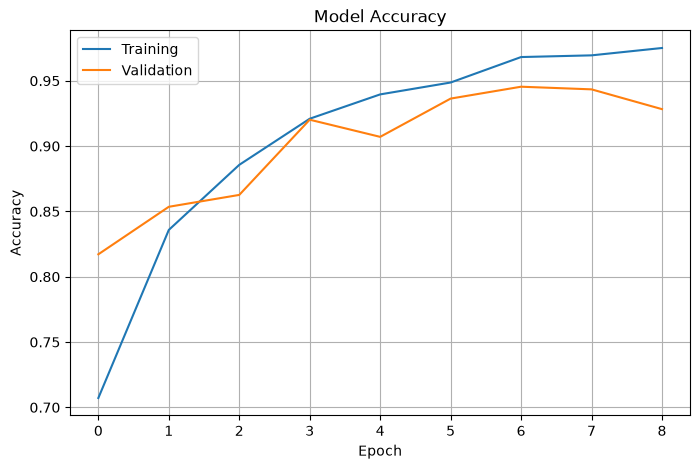

In [9]:
# Visualize accuracy

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.savefig(FIGURES_DIR / "accuracy.png")
plt.show()

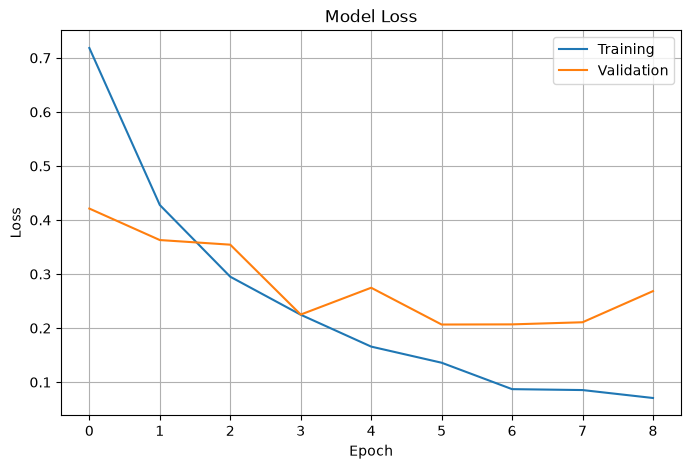

In [10]:

# Visualize loss

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.savefig(FIGURES_DIR / "loss.png")
plt.show()

In [11]:
# load the best model 
best_model = tf.keras.models.load_model(
    MODELS_DIR / "best_model.keras"
)

print("best model loaded!")

best model loaded!


In [12]:
# evaluates your trained CNN on the test dataset to measure how well 
# it classifies brain MRI images it hasn't seen during training.
test_loss, test_accuracy = best_model.evaluate(
    X_test,
    y_test
)

print(f"Test loss: {test_loss:.4f}")
print(f"Test Accuract: {test_accuracy:.4f}")


31/31 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.9172 - loss: 0.2722
Test loss: 0.2722
Test Accuract: 0.9172


In [13]:
# Generate predictions
# make my CNN predict the classes of test MRI images and compares
# its predictions with the real labels
probabilities = best_model.predict(
    X_test,
    batch_size=BATCH_SIZE
)

y_pred = np.argmax(probabilities, axis=1)

print("Predictions:", y_pred[:10])
print("actual:", y_test[:10])

124/124 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step
Predictions: [0 2 1 2 3 3 1 3 2 0]
actual: [0 2 1 2 3 3 1 3 2 0]


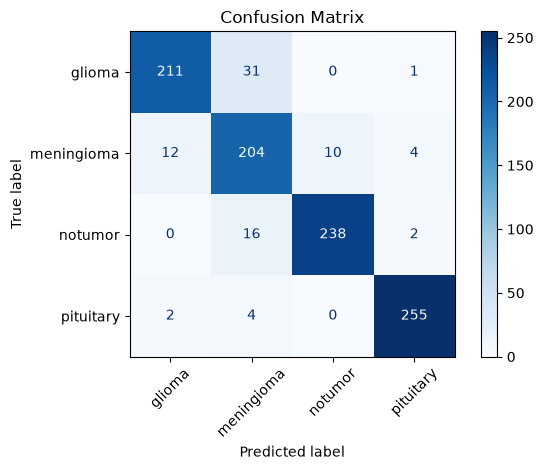

In [14]:
# confustion matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(len(class_names))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(cmap="Blues", xticks_rotation=45)

plt.title("Confusion Matrix")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "confusion_matrix.png")
plt.show()

In [15]:
# i generates a classification report
# to evaluate how well your CNN predicts each brain MRI class

report = classification_report(
    y_test,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
)

print(report)

              precision    recall  f1-score   support

      glioma       0.94      0.87      0.90       243
  meningioma       0.80      0.89      0.84       230
     notumor       0.96      0.93      0.94       256
   pituitary       0.97      0.98      0.98       261

    accuracy                           0.92       990
   macro avg       0.92      0.92      0.92       990
weighted avg       0.92      0.92      0.92       990



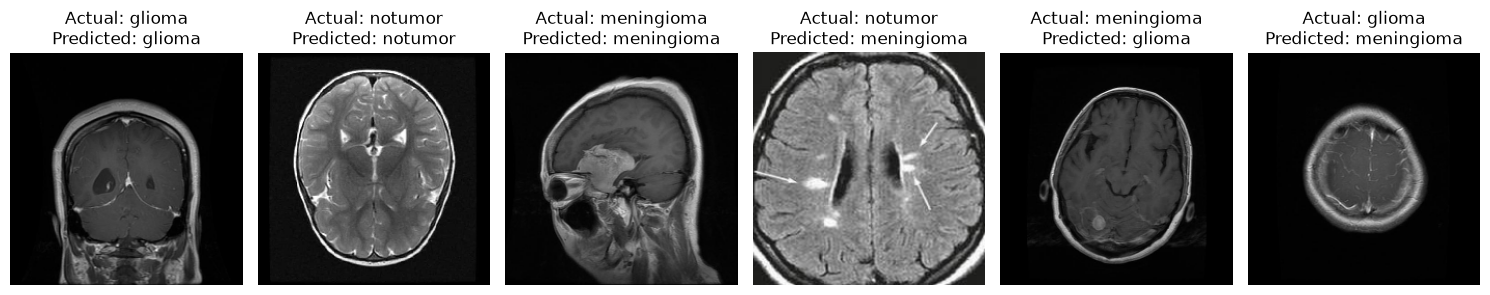

In [16]:
# here i display examples of MRI images that my
# CNN classified correctly and incorrectly
correct_indices = np.where(y_pred == y_test)[0]
wrong_indices = np.where(y_pred != y_test)[0]

samples = np.concatenate([
    correct_indices[:3],
    wrong_indices[:3]
])

if len(samples) == 0:
    print("No samples available.")
else:
    fig, axes = plt.subplots(
        1,
        len(samples),
        figsize=(15, 4)
    )

    axes = np.atleast_1d(axes)

    for ax, i in zip(axes, samples):

        ax.imshow(X_test[i])

        actual = class_names[y_test[i]]
        predicted = class_names[y_pred[i]]

        ax.set_title(
            f"Actual: {actual}\nPredicted: {predicted}"
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [17]:
metrics = {
    "test_accuracy": float(test_accuracy),
    "test_loss": float(test_loss),
    "training_seconds": float(training_time)
}

with open(MODELS_DIR / "metrics.json", "w") as file:
    json.dump(metrics, file, indent=4)


print("Evaluation fesults saved!")

Evaluation fesults saved!
